# Assignment 09: Feature-Importance Visualization for Vehicle Efficiency

### Domain
Automotive powertrain efficiency, fuel-consumption analysis and Explainable AI (XAI)

## Aim
Investigate which simulated vehicle attributes influence fuel-consumption predictions and compare several feature-importance approaches.

### Techniques Compared
- Mean Decrease in Impurity (MDI)
- Permutation Feature Importance (PFI)
- Mutual Information (MI)
- Partial Dependence Plots (PDP)
- Random-noise sanity check

The experiment combines model-based and statistical views of feature relevance rather than relying on a single importance measure.

In [1]:
# ============================================================
# STEP 1 — Import Required Libraries
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay
)

from sklearn.feature_selection import (
    mutual_info_regression
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# STEP 2 — Set Random Seed
# ============================================================

SEED = 17

np.random.seed(SEED)

print("Random seed:", SEED)

Random seed: 17


In [3]:
# ============================================================
# STEP 3 — Generate Synthetic Automotive Dataset
# ============================================================

n = 720

# Physical vehicle attributes
engine_displacement_L = np.random.uniform(
    1.0, 5.0, n
)

vehicle_weight_kg = (
    900
    + engine_displacement_L * 320
    + np.random.normal(0, 100, n)
)

horsepower = (
    55
    + engine_displacement_L * 42
    + np.random.normal(0, 18, n)
)

aerodynamic_drag_coefficient = np.random.uniform(
    0.22, 0.42, n
)

frontal_area_m2 = np.random.uniform(
    1.8, 3.2, n
)

tire_rolling_resistance = np.random.uniform(
    0.008, 0.015, n
)

transmission_efficiency = np.random.uniform(
    0.78, 0.96, n
)

# Completely unrelated random feature
random_noise = np.random.normal(
    0, 1, n
)

# ------------------------------------------------------------
# Synthetic fuel consumption relationship
# Lower value = better fuel economy
# ------------------------------------------------------------

fuel_consumption_L_per_100km = (
    3.0
    + 0.85 * engine_displacement_L
    + 0.0028 * vehicle_weight_kg
    + 0.008 * horsepower
    + 9.0 * aerodynamic_drag_coefficient
    + 1.8 * frontal_area_m2
    + 220 * tire_rolling_resistance
    - 4.0 * transmission_efficiency
    + 0.25 * np.sin(engine_displacement_L * 2)
    + np.random.normal(0, 0.6, n)
)

fuel_consumption_L_per_100km = np.clip(
    fuel_consumption_L_per_100km,
    3,
    None
)

print("Synthetic automotive dataset generated.")
print("Number of records:", n)

Synthetic automotive dataset generated.
Number of records: 720


In [4]:
# ============================================================
# STEP 4 — Create Automotive DataFrame
# ============================================================

auto_df = pd.DataFrame({

    "engine_displacement_L":
        engine_displacement_L,

    "vehicle_weight_kg":
        vehicle_weight_kg,

    "horsepower":
        horsepower,

    "aerodynamic_drag_coefficient":
        aerodynamic_drag_coefficient,

    "frontal_area_m2":
        frontal_area_m2,

    "tire_rolling_resistance":
        tire_rolling_resistance,

    "transmission_efficiency":
        transmission_efficiency,

    "random_noise":
        random_noise,

    "fuel_consumption_L_per_100km":
        fuel_consumption_L_per_100km
})

display(
    auto_df.head()
)

,engine_displacement_L,vehicle_weight_kg,horsepower,aerodynamic_drag_coefficient,frontal_area_m2,tire_rolling_resistance,transmission_efficiency,random_noise,fuel_consumption_L_per_100km
0,2.178660,1586.037777,179.584597,0.346156,2.224388,0.010752,0.915180,1.621438,16.460288
1,3.122347,1940.098648,223.350477,0.224346,2.700481,0.013290,0.811649,0.917025,19.828477
2,1.766083,1654.947929,121.715662,0.297252,2.186646,0.010329,0.855854,-1.196053,15.706134
3,1.271601,1131.947350,114.930190,0.407732,2.291042,0.009005,0.841354,-1.121869,15.796269
4,4.147942,2294.670082,235.808683,0.245039,1.877481,0.009298,0.809889,0.097091,18.928874


In [5]:
# ============================================================
# STEP 5 — Dataset Inspection
# ============================================================

print("Dataset shape:")
print(auto_df.shape)

print("\nColumn names:")
print(auto_df.columns.tolist())

print("\nData types:")
print(auto_df.dtypes)

print("\nMissing values:")
print(auto_df.isnull().sum())

Dataset shape:
(720, 9)

Column names:
['engine_displacement_L', 'vehicle_weight_kg', 'horsepower', 'aerodynamic_drag_coefficient', 'frontal_area_m2', 'tire_rolling_resistance', 'transmission_efficiency', 'random_noise', 'fuel_consumption_L_per_100km']

Data types:
engine_displacement_L           float64
vehicle_weight_kg               float64
horsepower                      float64
aerodynamic_drag_coefficient    float64
frontal_area_m2                 float64
tire_rolling_resistance         float64
transmission_efficiency         float64
random_noise                    float64
fuel_consumption_L_per_100km    float64
dtype: object

Missing values:
engine_displacement_L           0
vehicle_weight_kg               0
horsepower                      0
aerodynamic_drag_coefficient    0
frontal_area_m2                 0
tire_rolling_resistance         0
transmission_efficiency         0
random_noise                    0
fuel_consumption_L_per_100km    0
dtype: int64


In [6]:
# ============================================================
# STEP 6 — Descriptive Statistics
# ============================================================

display(
    auto_df.describe().round(3)
)

,engine_displacement_L,vehicle_weight_kg,horsepower,aerodynamic_drag_coefficient,frontal_area_m2,tire_rolling_resistance,transmission_efficiency,random_noise,fuel_consumption_L_per_100km
count,720.000,720.000,720.000,720.000,720.000,720.000,720.000,720.000,720.000
mean,3.044,1875.628,184.257,0.317,2.498,0.012,0.872,-0.030,18.747
std,1.134,376.621,50.885,0.058,0.404,0.002,0.052,1.035,2.663
min,1.009,879.634,70.937,0.220,1.803,0.008,0.781,-3.738,12.269
25%,2.091,1577.175,143.339,0.266,2.158,0.010,0.828,-0.764,16.611
50%,3.063,1903.837,186.793,0.317,2.476,0.012,0.876,-0.012,18.747
75%,4.036,2195.691,224.812,0.367,2.837,0.013,0.917,0.675,20.912
max,4.999,2804.089,294.777,0.420,3.199,0.015,0.960,3.508,25.140


In [7]:
# ============================================================
# STEP 7 — Feature Correlation with Target
# ============================================================

target_column = (
    "fuel_consumption_L_per_100km"
)

correlation = (
    auto_df
    .corr(numeric_only=True)[target_column]
    .sort_values(
        ascending=False
    )
)

print(
    "Correlation with fuel consumption:"
)

display(
    correlation.to_frame(
        name="Correlation"
    )
)

Correlation with fuel consumption:


,Correlation
fuel_consumption_L_per_100km,1.000000
engine_displacement_L,0.882757
vehicle_weight_kg,0.882472
horsepower,0.848017
frontal_area_m2,0.226730
tire_rolling_resistance,0.223980
aerodynamic_drag_coefficient,0.198682
random_noise,0.045344
transmission_efficiency,-0.087696


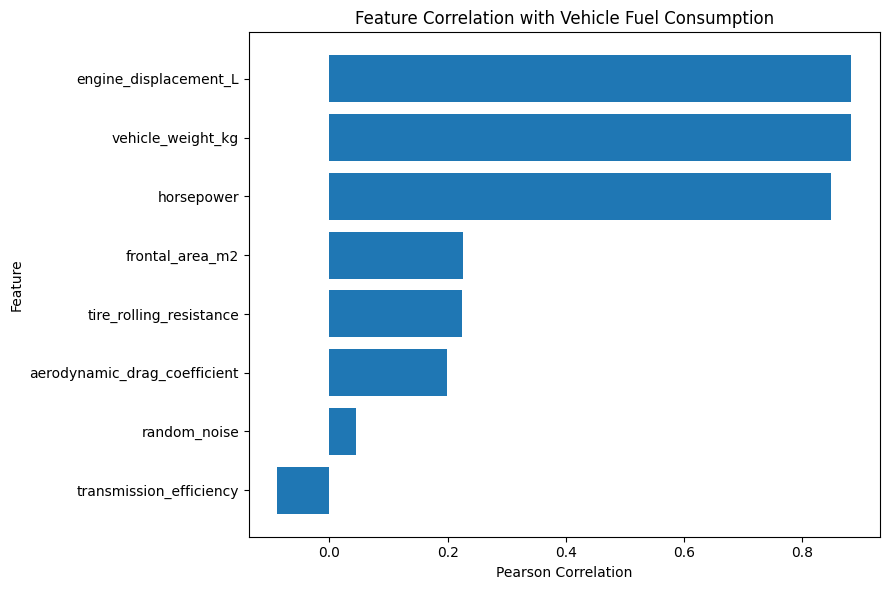

In [8]:
# ============================================================
# STEP 8 — Correlation Visualization
# ============================================================

feature_correlations = (
    correlation
    .drop(target_column)
    .sort_values()
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    feature_correlations.index,
    feature_correlations.values
)

plt.xlabel(
    "Pearson Correlation"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Feature Correlation with Vehicle Fuel Consumption"
)

plt.tight_layout()

plt.show()

In [9]:
# ============================================================
# STEP 9 — Separate Features and Target
# ============================================================

X = auto_df.drop(
    columns=[target_column]
)

y = auto_df[target_column]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (720, 8)
Target shape: (720,)

Features:
['engine_displacement_L', 'vehicle_weight_kg', 'horsepower', 'aerodynamic_drag_coefficient', 'frontal_area_m2', 'tire_rolling_resistance', 'transmission_efficiency', 'random_noise']


In [10]:
# ============================================================
# STEP 10 — Train/Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 576
Testing samples : 144


In [11]:
# ============================================================
# STEP 11 — Train Random Forest Regressor
# ============================================================

rf = RandomForestRegressor(
    n_estimators=280,
    random_state=SEED,
    n_jobs=-1,
    max_features=1.0
)

rf.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [12]:
# ============================================================
# STEP 12 — Train Gradient Boosting Regressor
# ============================================================

gbr = GradientBoostingRegressor(
    n_estimators=230,
    learning_rate=0.04,
    max_depth=3,
    random_state=SEED
)

gbr.fit(
    X_train,
    y_train
)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [13]:
# ============================================================
# STEP 13 — Evaluate Regression Models
# ============================================================

models = {
    "Random Forest": rf,
    "Gradient Boosting": gbr
}

results = []

for name, model in models.items():

    predictions = model.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(
    results
)

display(
    results_df.round(4)
)

,Model,MAE,RMSE,R2
0,Random Forest,0.5747,0.7047,0.9343
1,Gradient Boosting,0.5071,0.6319,0.9472


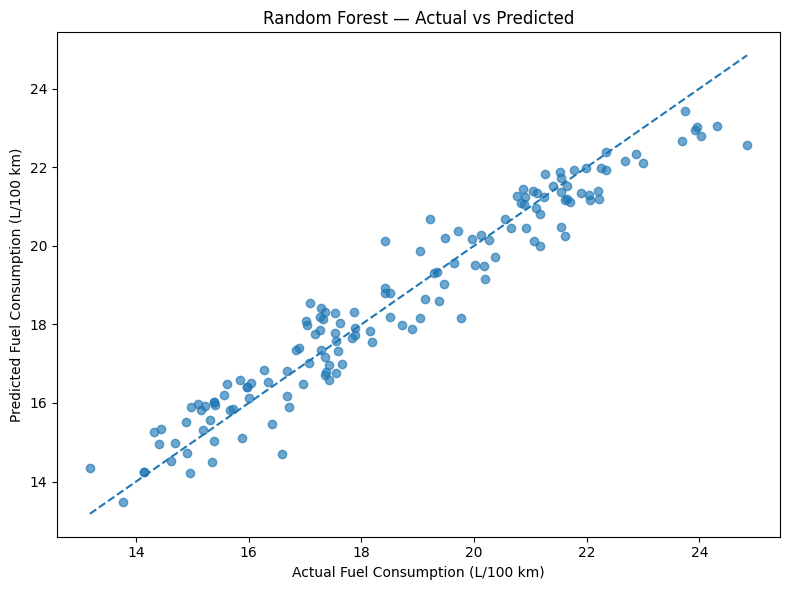

In [14]:
# ============================================================
# STEP 14 — Actual vs Predicted Fuel Consumption
# ============================================================

rf_predictions = rf.predict(
    X_test
)

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.65
)

min_value = min(
    y_test.min(),
    rf_predictions.min()
)

max_value = max(
    y_test.max(),
    rf_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Fuel Consumption (L/100 km)"
)

plt.ylabel(
    "Predicted Fuel Consumption (L/100 km)"
)

plt.title(
    "Random Forest — Actual vs Predicted"
)

plt.tight_layout()

plt.show()

In [15]:
# ============================================================
# STEP 15 — Mean Decrease in Impurity (MDI)
# ============================================================

mdi_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(
    ascending=False
)

print(
    "Mean Decrease in Impurity (MDI):"
)

display(
    mdi_importance.to_frame(
        name="MDI Importance"
    )
)

Mean Decrease in Impurity (MDI):


,MDI Importance
engine_displacement_L,0.486979
vehicle_weight_kg,0.327338
frontal_area_m2,0.073456
aerodynamic_drag_coefficient,0.042254
tire_rolling_resistance,0.033408
horsepower,0.019834
transmission_efficiency,0.010159
random_noise,0.006572


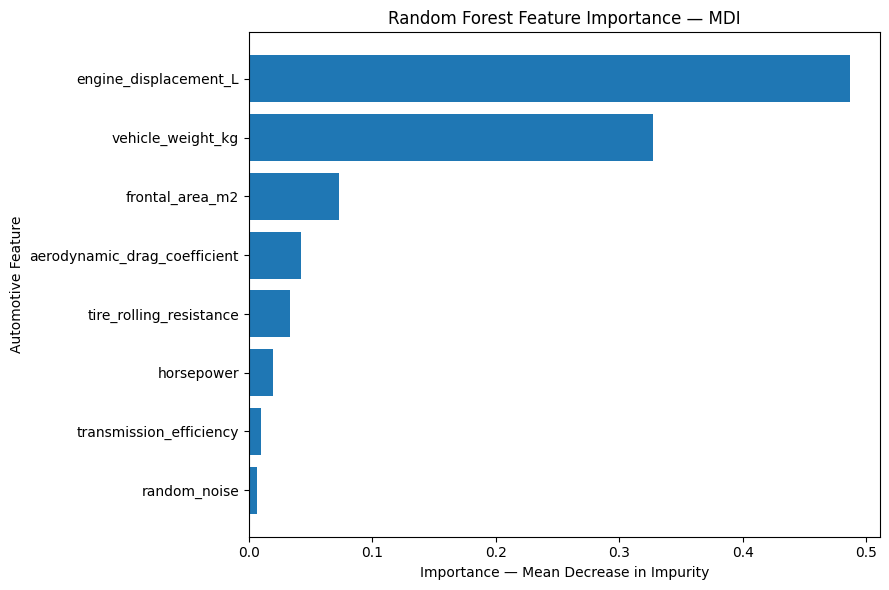

In [16]:
# ============================================================
# STEP 16 — Visualize MDI Feature Importance
# ============================================================

plt.figure(
    figsize=(9, 6)
)

mdi_sorted = mdi_importance.sort_values()

plt.barh(
    mdi_sorted.index,
    mdi_sorted.values
)

plt.xlabel(
    "Importance — Mean Decrease in Impurity"
)

plt.ylabel(
    "Automotive Feature"
)

plt.title(
    "Random Forest Feature Importance — MDI"
)

plt.tight_layout()

plt.show()

In [17]:
# ============================================================
# STEP 17 — Normalize MDI Importance
# ============================================================

mdi_normalized = (
    mdi_importance
    / mdi_importance.sum()
)

mdi_table = pd.DataFrame({
    "Feature": mdi_normalized.index,
    "MDI Importance": mdi_normalized.values
})

display(
    mdi_table.round(4)
)

,Feature,MDI Importance
0,engine_displacement_L,0.4870
1,vehicle_weight_kg,0.3273
2,frontal_area_m2,0.0735
3,aerodynamic_drag_coefficient,0.0423
4,tire_rolling_resistance,0.0334
5,horsepower,0.0198
6,transmission_efficiency,0.0102
7,random_noise,0.0066


In [18]:
# ============================================================
# STEP 18 — Permutation Feature Importance (PFI)
# ============================================================

pfi = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=20,
    random_state=SEED,
    scoring="r2",
    n_jobs=-1
)

pfi_mean = pd.Series(
    pfi.importances_mean,
    index=X.columns
)

pfi_std = pd.Series(
    pfi.importances_std,
    index=X.columns
)

pfi_table = pd.DataFrame({
    "Feature": X.columns,
    "PFI Mean": pfi_mean.values,
    "PFI Std": pfi_std.values
}).sort_values(
    "PFI Mean",
    ascending=False
)

display(
    pfi_table.round(4)
)

,Feature,PFI Mean,PFI Std
0,engine_displacement_L,0.5050,0.0498
1,vehicle_weight_kg,0.3198,0.0277
4,frontal_area_m2,0.0943,0.0090
5,tire_rolling_resistance,0.0393,0.0059
3,aerodynamic_drag_coefficient,0.0375,0.0056
2,horsepower,0.0155,0.0024
6,transmission_efficiency,0.0047,0.0011
7,random_noise,-0.0008,0.0004


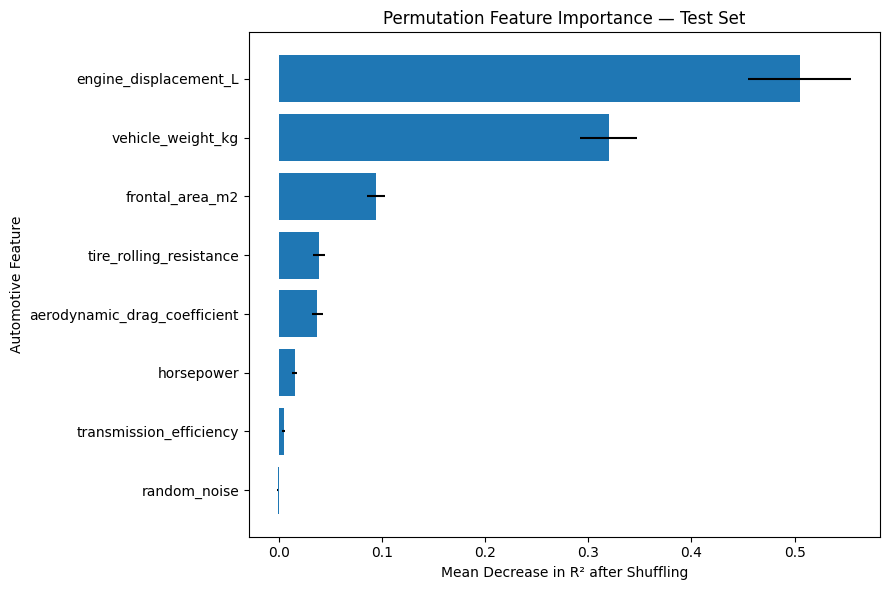

In [19]:
# ============================================================
# STEP 19 — Visualize Permutation Feature Importance
# ============================================================

pfi_sorted = pfi_table.sort_values(
    "PFI Mean"
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    pfi_sorted["Feature"],
    pfi_sorted["PFI Mean"],
    xerr=pfi_sorted["PFI Std"]
)

plt.xlabel(
    "Mean Decrease in R² after Shuffling"
)

plt.ylabel(
    "Automotive Feature"
)

plt.title(
    "Permutation Feature Importance — Test Set"
)

plt.tight_layout()

plt.show()

In [20]:
# ============================================================
# STEP 20 — Compare MDI and PFI
# ============================================================

importance_comparison = pd.DataFrame({
    "MDI": mdi_importance,
    "Permutation Importance": pfi_mean
})

importance_comparison = (
    importance_comparison
    .sort_values(
        "MDI",
        ascending=False
    )
)

display(
    importance_comparison.round(4)
)

,MDI,Permutation Importance
engine_displacement_L,0.4870,0.5050
vehicle_weight_kg,0.3273,0.3198
frontal_area_m2,0.0735,0.0943
aerodynamic_drag_coefficient,0.0423,0.0375
tire_rolling_resistance,0.0334,0.0393
horsepower,0.0198,0.0155
transmission_efficiency,0.0102,0.0047
random_noise,0.0066,-0.0008


In [21]:
# ============================================================
# STEP 21 — Mutual Information Feature Importance
# ============================================================

mi_values = mutual_info_regression(
    X_train,
    y_train,
    random_state=SEED
)

mi_importance = pd.Series(
    mi_values,
    index=X.columns
).sort_values(
    ascending=False
)

mi_table = pd.DataFrame({
    "Feature": mi_importance.index,
    "Mutual Information": mi_importance.values
})

display(
    mi_table.round(4)
)

,Feature,Mutual Information
0,vehicle_weight_kg,0.7232
1,engine_displacement_L,0.6632
2,horsepower,0.5947
3,frontal_area_m2,0.0577
4,random_noise,0.0466
5,tire_rolling_resistance,0.0443
6,aerodynamic_drag_coefficient,0.0000
7,transmission_efficiency,0.0000


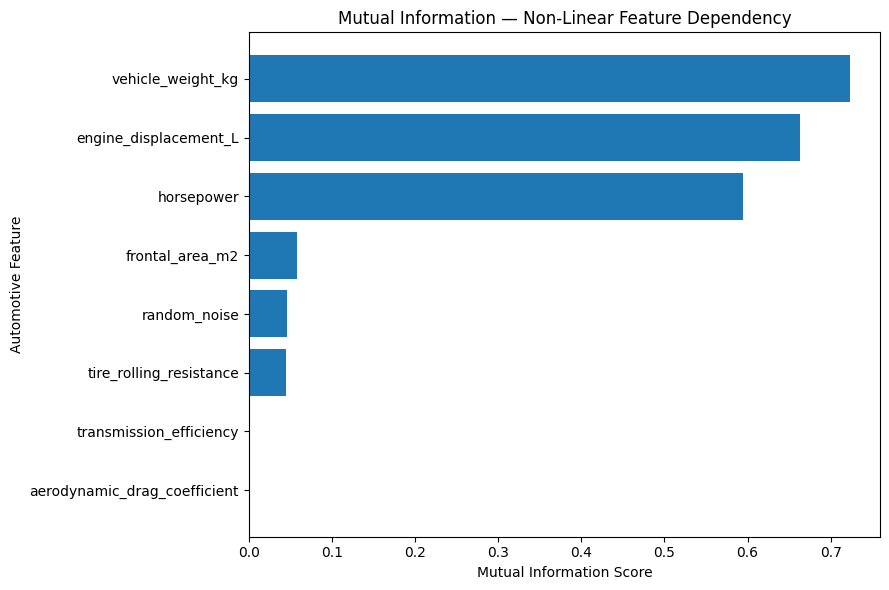

In [22]:
# ============================================================
# STEP 22 — Visualize Mutual Information
# ============================================================

mi_sorted = mi_importance.sort_values()

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    mi_sorted.index,
    mi_sorted.values
)

plt.xlabel(
    "Mutual Information Score"
)

plt.ylabel(
    "Automotive Feature"
)

plt.title(
    "Mutual Information — Non-Linear Feature Dependency"
)

plt.tight_layout()

plt.show()

In [23]:
# ============================================================
# STEP 23 — Combined Feature Importance Table
# ============================================================

combined_importance = pd.DataFrame({

    "MDI":
        mdi_importance,

    "Permutation Importance":
        pfi_mean,

    "Mutual Information":
        mi_importance
})

display(
    combined_importance
    .sort_values(
        "MDI",
        ascending=False
    )
    .round(4)
)

,MDI,Permutation Importance,Mutual Information
engine_displacement_L,0.4870,0.5050,0.6632
vehicle_weight_kg,0.3273,0.3198,0.7232
frontal_area_m2,0.0735,0.0943,0.0577
aerodynamic_drag_coefficient,0.0423,0.0375,0.0000
tire_rolling_resistance,0.0334,0.0393,0.0443
horsepower,0.0198,0.0155,0.5947
transmission_efficiency,0.0102,0.0047,0.0000
random_noise,0.0066,-0.0008,0.0466


In [24]:
# ============================================================
# STEP 24 — Normalize Importance Scores for Comparison
# ============================================================

comparison_normalized = pd.DataFrame({

    "MDI":
        mdi_importance / mdi_importance.sum(),

    "PFI":
        pfi_mean.clip(lower=0)
        / pfi_mean.clip(lower=0).sum(),

    "MI":
        mi_importance / mi_importance.sum()
})

display(
    comparison_normalized
    .sort_values(
        "MDI",
        ascending=False
    )
    .round(4)
)

,MDI,PFI,MI
engine_displacement_L,0.4870,0.4970,0.3114
vehicle_weight_kg,0.3273,0.3147,0.3396
frontal_area_m2,0.0735,0.0928,0.0271
aerodynamic_drag_coefficient,0.0423,0.0369,0.0000
tire_rolling_resistance,0.0334,0.0387,0.0208
horsepower,0.0198,0.0153,0.2793
transmission_efficiency,0.0102,0.0046,0.0000
random_noise,0.0066,0.0000,0.0219


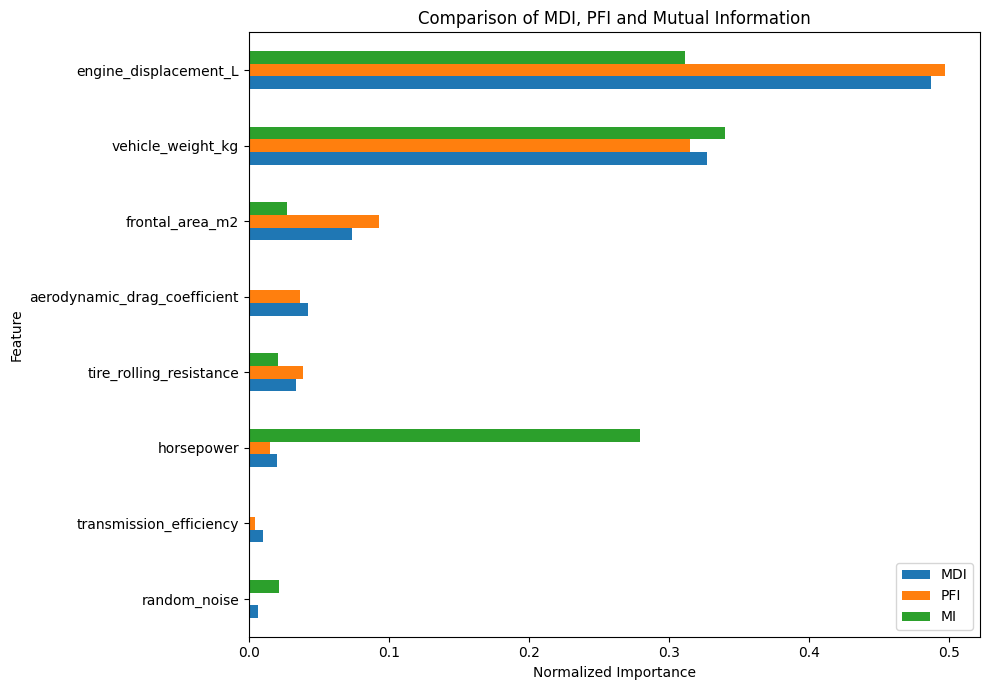

In [25]:
# ============================================================
# STEP 25 — Comparative Feature Importance Visualization
# ============================================================

plot_data = comparison_normalized.sort_values(
    "MDI"
)

ax = plot_data.plot(
    kind="barh",
    figsize=(10, 7)
)

ax.set_xlabel(
    "Normalized Importance"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Comparison of MDI, PFI and Mutual Information"
)

plt.tight_layout()

plt.show()

In [26]:
# ============================================================
# STEP 26 — Identify Important Automotive Features
# ============================================================

top_mdi = mdi_importance.head(5)

top_pfi = pfi_mean.sort_values(
    ascending=False
).head(5)

top_mi = mi_importance.head(5)

print("Top features according to MDI:")
print(top_mdi)

print("\nTop features according to PFI:")
print(top_pfi)

print("\nTop features according to Mutual Information:")
print(top_mi)

Top features according to MDI:
engine_displacement_L           0.486979
vehicle_weight_kg               0.327338
frontal_area_m2                 0.073456
aerodynamic_drag_coefficient    0.042254
tire_rolling_resistance         0.033408
dtype: float64

Top features according to PFI:
engine_displacement_L           0.505044
vehicle_weight_kg               0.319779
frontal_area_m2                 0.094340
tire_rolling_resistance         0.039292
aerodynamic_drag_coefficient    0.037495
dtype: float64

Top features according to Mutual Information:
vehicle_weight_kg        0.723153
engine_displacement_L    0.663247
horsepower               0.594732
frontal_area_m2          0.057718
random_noise             0.046554
dtype: float64


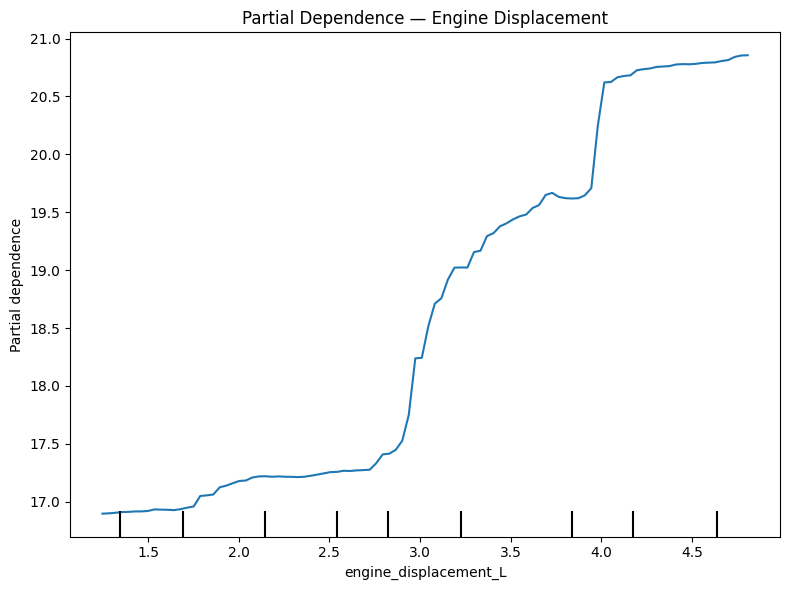

In [27]:
# ============================================================
# STEP 27 — Partial Dependence Plot: Engine Displacement
# ============================================================

feature = "engine_displacement_L"

fig, ax = plt.subplots(
    figsize=(8, 6)
)

PartialDependenceDisplay.from_estimator(
    rf,
    X_test,
    [feature],
    ax=ax
)

ax.set_title(
    "Partial Dependence — Engine Displacement"
)

plt.tight_layout()

plt.show()

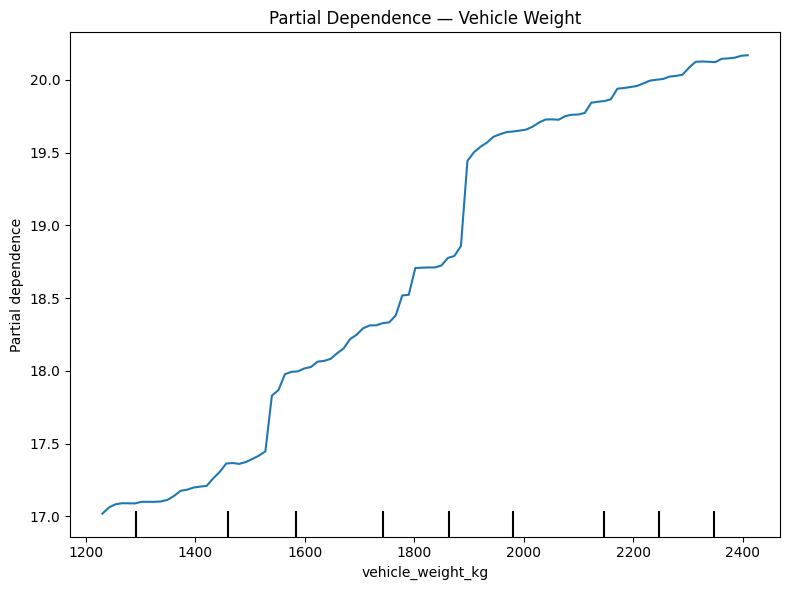

In [28]:
# ============================================================
# STEP 28 — Partial Dependence Plot: Vehicle Weight
# ============================================================

feature = "vehicle_weight_kg"

fig, ax = plt.subplots(
    figsize=(8, 6)
)

PartialDependenceDisplay.from_estimator(
    rf,
    X_test,
    [feature],
    ax=ax
)

ax.set_title(
    "Partial Dependence — Vehicle Weight"
)

plt.tight_layout()

plt.show()

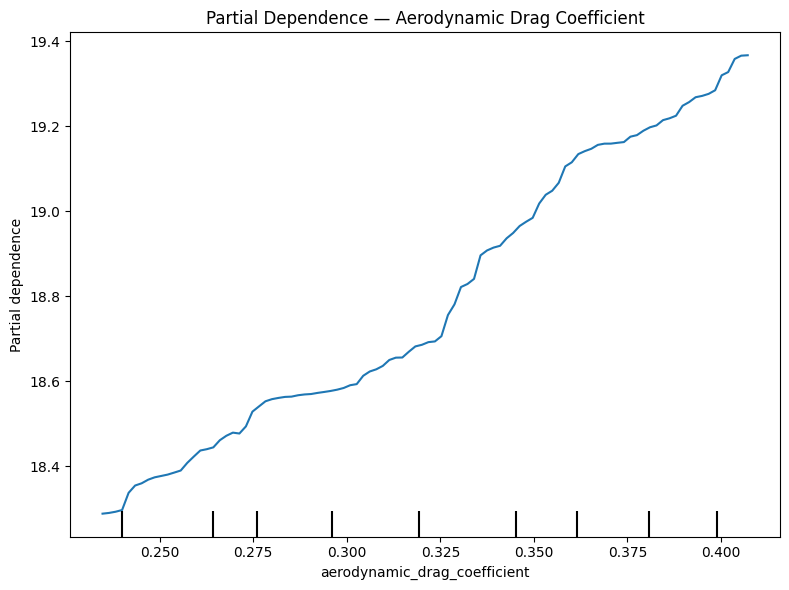

In [29]:
# ============================================================
# STEP 29 — Partial Dependence Plot: Aerodynamic Drag
# ============================================================

feature = "aerodynamic_drag_coefficient"

fig, ax = plt.subplots(
    figsize=(8, 6)
)

PartialDependenceDisplay.from_estimator(
    rf,
    X_test,
    [feature],
    ax=ax
)

ax.set_title(
    "Partial Dependence — Aerodynamic Drag Coefficient"
)

plt.tight_layout()

plt.show()

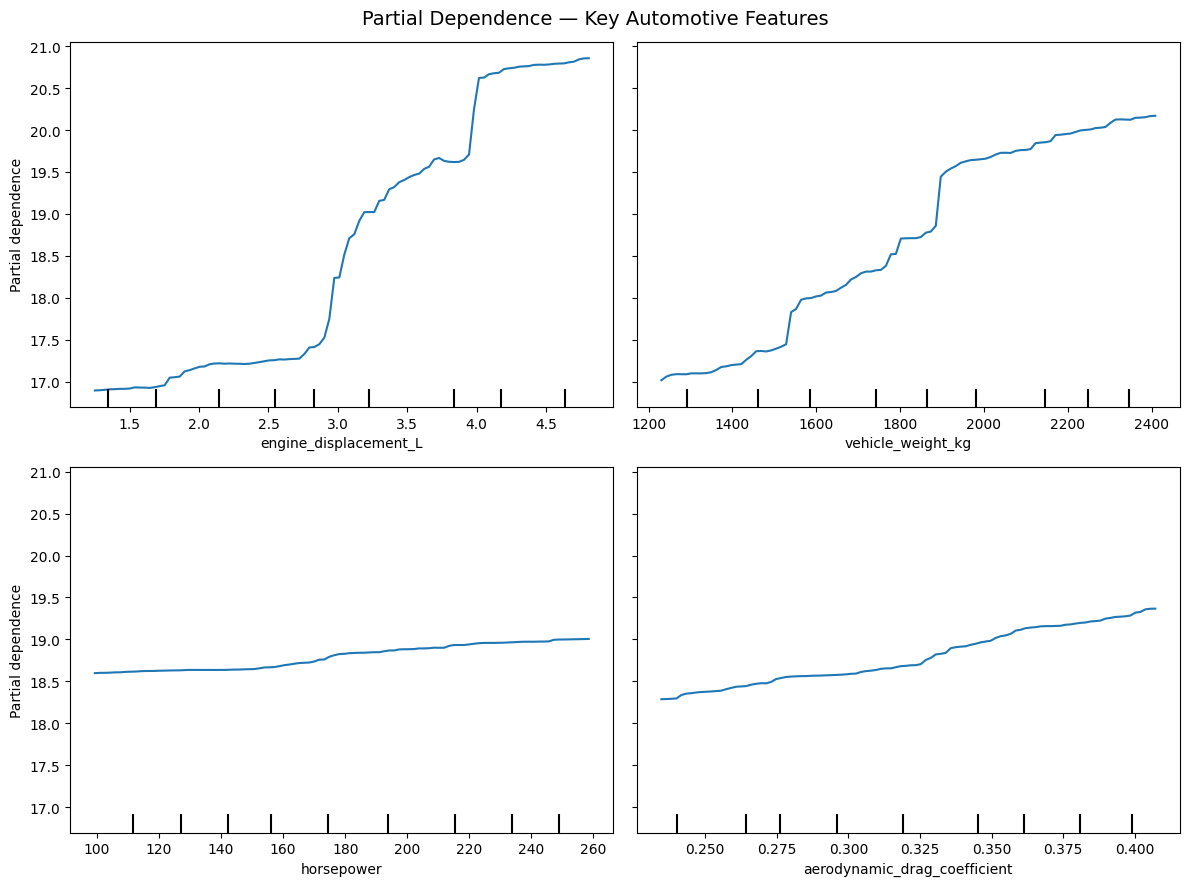

In [30]:
# ============================================================
# STEP 30 — Partial Dependence for Multiple Important Features
# ============================================================

top_features = [
    "engine_displacement_L",
    "vehicle_weight_kg",
    "horsepower",
    "aerodynamic_drag_coefficient"
]

fig, ax = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 9)
)

PartialDependenceDisplay.from_estimator(
    rf,
    X_test,
    top_features,
    ax=ax
)

plt.suptitle(
    "Partial Dependence — Key Automotive Features",
    fontsize=14
)

plt.tight_layout()

plt.show()

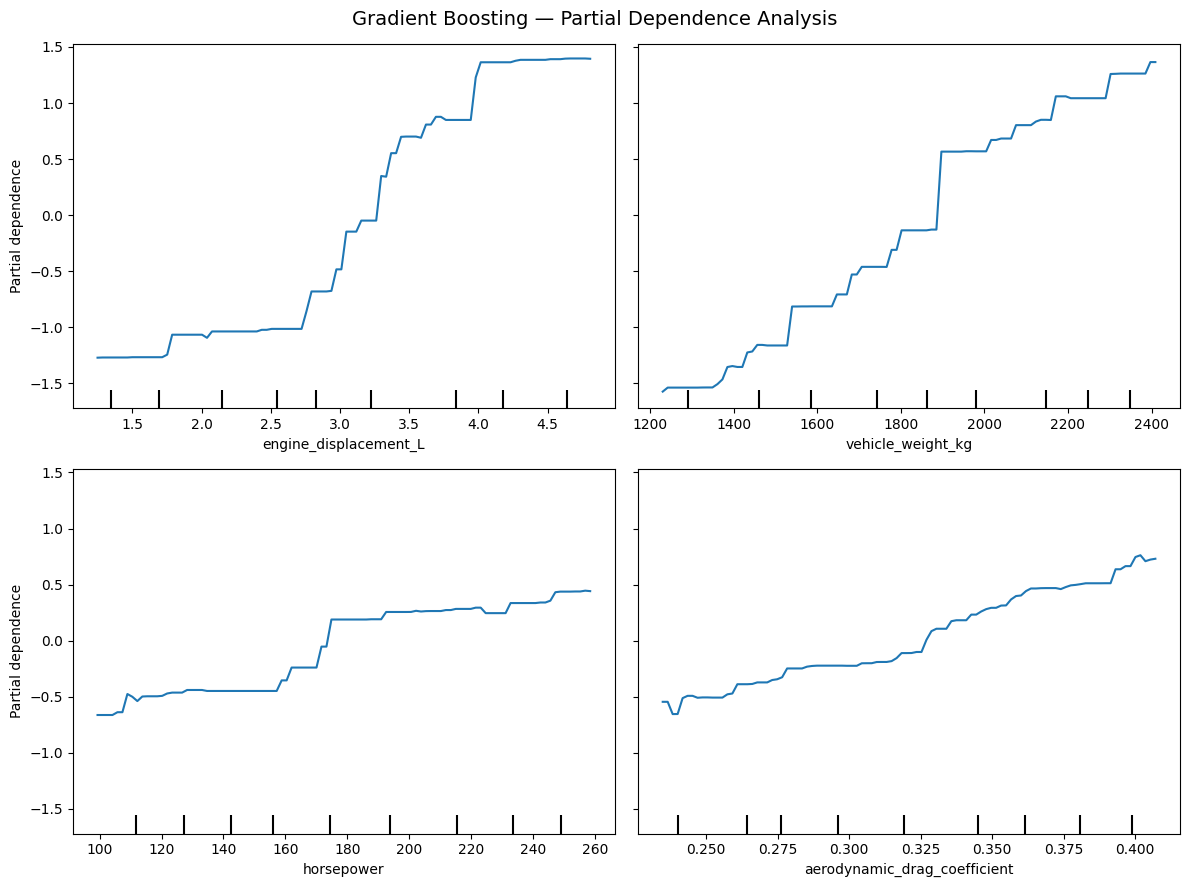

In [31]:
# ============================================================
# STEP 31 — PDP using Gradient Boosting Model
# ============================================================

fig, ax = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 9)
)

PartialDependenceDisplay.from_estimator(
    gbr,
    X_test,
    top_features,
    ax=ax
)

plt.suptitle(
    "Gradient Boosting — Partial Dependence Analysis",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [32]:
# ============================================================
# STEP 32 — Noise Immunity Test
# ============================================================

noise_columns = [
    "random_noise"
]

print(
    "Noise feature statistics:"
)

display(
    auto_df[
        noise_columns
    ].describe()
)

Noise feature statistics:


,random_noise
count,720.000000
mean,-0.029894
std,1.034865
min,-3.737605
25%,-0.764155
50%,-0.011860
75%,0.674583
max,3.508049


In [33]:
# ============================================================
# STEP 33 — Correlation of Noise with Target
# ============================================================

noise_correlation = (
    auto_df[
        "random_noise"
    ].corr(
        auto_df[
            target_column
        ]
    )
)

print(
    f"Correlation between random noise "
    f"and fuel consumption: "
    f"{noise_correlation:.6f}"
)

Correlation between random noise and fuel consumption: 0.045344


In [34]:
# ============================================================
# STEP 34 — Noise Feature MDI Importance
# ============================================================

noise_mdi = mdi_importance[
    "random_noise"
]

print(
    f"Random noise MDI importance: "
    f"{noise_mdi:.6f}"
)

Random noise MDI importance: 0.006572


In [35]:
# ============================================================
# STEP 35 — Noise Feature Permutation Importance
# ============================================================

noise_pfi_mean = pfi_mean[
    "random_noise"
]

noise_pfi_std = pfi_std[
    "random_noise"
]

print(
    f"Random noise PFI mean: "
    f"{noise_pfi_mean:.6f}"
)

print(
    f"Random noise PFI std : "
    f"{noise_pfi_std:.6f}"
)

Random noise PFI mean: -0.000794
Random noise PFI std : 0.000409


In [36]:
# ============================================================
# STEP 36 — Noise Feature Mutual Information
# ============================================================

noise_mi = mi_importance[
    "random_noise"
]

print(
    f"Random noise Mutual Information: "
    f"{noise_mi:.6f}"
)

Random noise Mutual Information: 0.046554


In [37]:
# ============================================================
# STEP 37 — Noise Immunity Summary
# ============================================================

noise_summary = pd.DataFrame({

    "Method": [
        "MDI",
        "Permutation Importance",
        "Mutual Information"
    ],

    "Random Noise Score": [
        noise_mdi,
        noise_pfi_mean,
        noise_mi
    ]
})

display(
    noise_summary.round(6)
)

,Method,Random Noise Score
0,MDI,0.006572
1,Permutation Importance,-0.000794
2,Mutual Information,0.046554


In [38]:
# ============================================================
# STEP 38 — Compare Noise Against Top Features
# ============================================================

comparison_features = [
    "engine_displacement_L",
    "vehicle_weight_kg",
    "horsepower",
    "aerodynamic_drag_coefficient",
    "random_noise"
]

noise_comparison = pd.DataFrame({

    "MDI":
        mdi_importance[
            comparison_features
        ],

    "PFI":
        pfi_mean[
            comparison_features
        ],

    "MI":
        mi_importance[
            comparison_features
        ]
})

display(
    noise_comparison.round(6)
)

,MDI,PFI,MI
engine_displacement_L,0.486979,0.505044,0.663247
vehicle_weight_kg,0.327338,0.319779,0.723153
horsepower,0.019834,0.015524,0.594732
aerodynamic_drag_coefficient,0.042254,0.037495,0.000000
random_noise,0.006572,-0.000794,0.046554


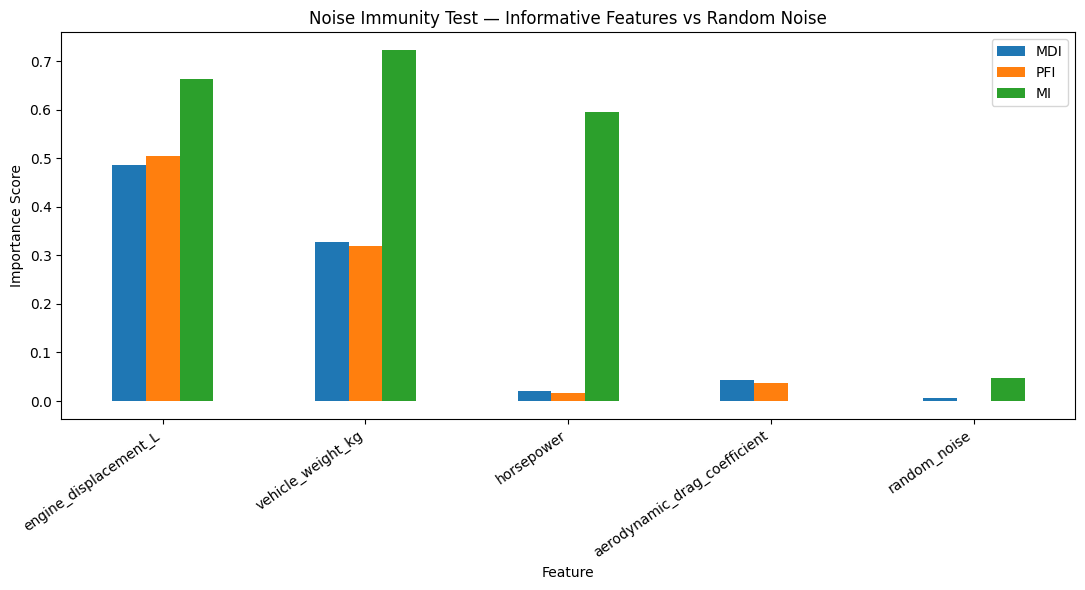

In [39]:
# ============================================================
# STEP 39 — Visualize Noise Immunity
# ============================================================

noise_plot = noise_comparison.copy()

ax = noise_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_xlabel(
    "Feature"
)

ax.set_ylabel(
    "Importance Score"
)

ax.set_title(
    "Noise Immunity Test — Informative Features vs Random Noise"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.show()

In [40]:
# ============================================================
# STEP 40 — Feature Ranking
# ============================================================

ranking_df = pd.DataFrame({

    "MDI Rank":
        mdi_importance.rank(
            ascending=False,
            method="min"
        ).astype(int),

    "PFI Rank":
        pfi_mean.rank(
            ascending=False,
            method="min"
        ).astype(int),

    "MI Rank":
        mi_importance.rank(
            ascending=False,
            method="min"
        ).astype(int)
})

ranking_df = ranking_df.sort_values(
    "MDI Rank"
)

display(
    ranking_df
)

,MDI Rank,PFI Rank,MI Rank
engine_displacement_L,1,1,2
vehicle_weight_kg,2,2,1
frontal_area_m2,3,3,4
aerodynamic_drag_coefficient,4,5,7
tire_rolling_resistance,5,4,6
horsepower,6,6,3
transmission_efficiency,7,7,7
random_noise,8,8,5


In [41]:
# ============================================================
# STEP 41 — Generate Automated Interpretation
# ============================================================

top_mdi_feature = (
    mdi_importance.idxmax()
)

top_pfi_feature = (
    pfi_mean.idxmax()
)

top_mi_feature = (
    mi_importance.idxmax()
)

print(
    "Feature with highest MDI importance:",
    top_mdi_feature
)

print(
    "Feature with highest PFI importance:",
    top_pfi_feature
)

print(
    "Feature with highest Mutual Information:",
    top_mi_feature
)

print(
    "\nRandom noise scores:"
)

print(
    "MDI:",
    round(noise_mdi, 6)
)

print(
    "PFI:",
    round(noise_pfi_mean, 6)
)

print(
    "MI :",
    round(noise_mi, 6)
)

Feature with highest MDI importance: engine_displacement_L
Feature with highest PFI importance: engine_displacement_L
Feature with highest Mutual Information: vehicle_weight_kg

Random noise scores:
MDI: 0.006572
PFI: -0.000794
MI : 0.046554


In [42]:
# ============================================================
# STEP 42 — Final XAI Feature Importance Table
# ============================================================

final_importance_table = pd.DataFrame({

    "MDI":
        mdi_importance,

    "Permutation Importance":
        pfi_mean,

    "Mutual Information":
        mi_importance,

    "MDI Rank":
        mdi_importance.rank(
            ascending=False,
            method="min"
        ).astype(int),

    "PFI Rank":
        pfi_mean.rank(
            ascending=False,
            method="min"
        ).astype(int),

    "MI Rank":
        mi_importance.rank(
            ascending=False,
            method="min"
        ).astype(int)
})

final_importance_table = (
    final_importance_table
    .sort_values("MDI", ascending=False)
)

display(
    final_importance_table.round(4)
)

,MDI,Permutation Importance,Mutual Information,MDI Rank,PFI Rank,MI Rank
engine_displacement_L,0.4870,0.5050,0.6632,1,1,2
vehicle_weight_kg,0.3273,0.3198,0.7232,2,2,1
frontal_area_m2,0.0735,0.0943,0.0577,3,3,4
aerodynamic_drag_coefficient,0.0423,0.0375,0.0000,4,5,7
tire_rolling_resistance,0.0334,0.0393,0.0443,5,4,6
horsepower,0.0198,0.0155,0.5947,6,6,3
transmission_efficiency,0.0102,0.0047,0.0000,7,7,7
random_noise,0.0066,-0.0008,0.0466,8,8,5


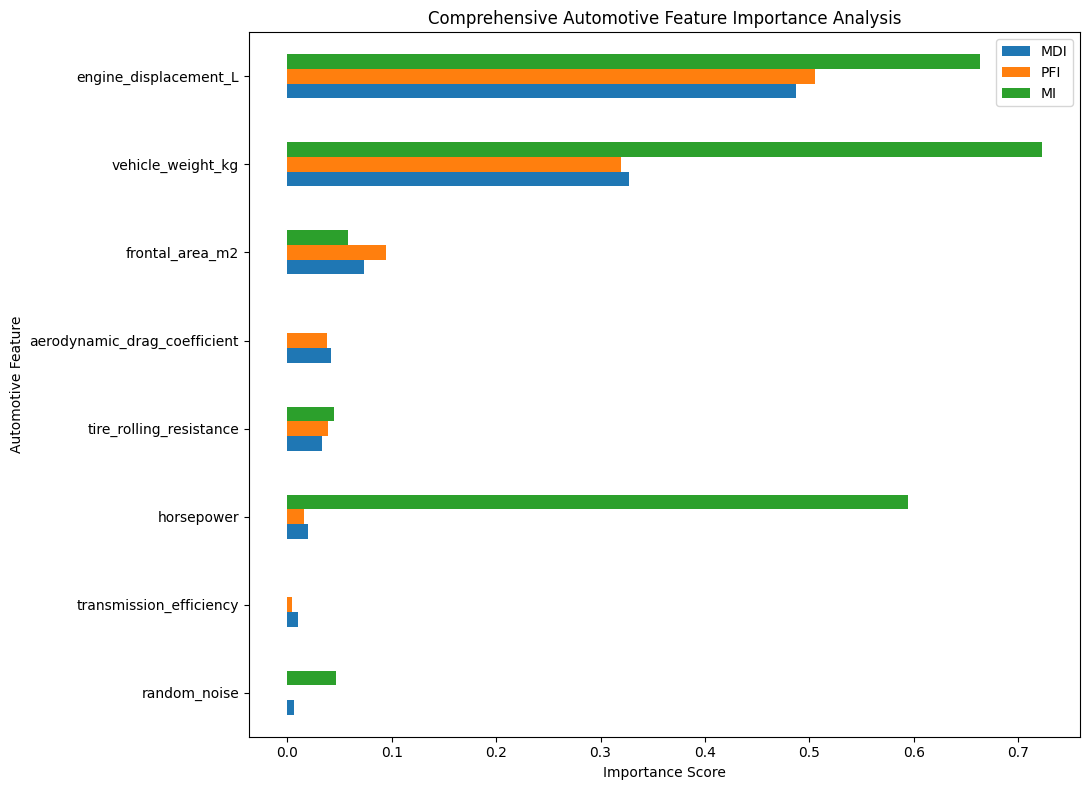

In [43]:
# ============================================================
# STEP 43 — Final Feature Importance Summary
# ============================================================

summary_features = [
    "engine_displacement_L",
    "vehicle_weight_kg",
    "horsepower",
    "aerodynamic_drag_coefficient",
    "frontal_area_m2",
    "tire_rolling_resistance",
    "transmission_efficiency",
    "random_noise"
]

summary_data = pd.DataFrame({

    "MDI":
        mdi_importance[
            summary_features
        ],

    "PFI":
        pfi_mean[
            summary_features
        ],

    "MI":
        mi_importance[
            summary_features
        ]
})

summary_data = summary_data.sort_values(
    "MDI"
)

summary_data.plot(
    kind="barh",
    figsize=(11, 8)
)

plt.xlabel(
    "Importance Score"
)

plt.ylabel(
    "Automotive Feature"
)

plt.title(
    "Comprehensive Automotive Feature Importance Analysis"
)

plt.tight_layout()

plt.show()

In [44]:
# ============================================================
# STEP 44 — Final Experiment Verification
# ============================================================

print("=" * 60)
print("ASSIGNMENT 09 — FINAL VERIFICATION")
print("=" * 60)

print(
    "\n1. Random Forest trained        :",
    hasattr(rf, "feature_importances_")
)

print(
    "2. Gradient Boosting trained    :",
    hasattr(gbr, "feature_importances_")
)

print(
    "3. MDI calculated               :",
    len(mdi_importance) == X.shape[1]
)

print(
    "4. PFI calculated               :",
    len(pfi_mean) == X.shape[1]
)

print(
    "5. Mutual Information calculated:",
    len(mi_importance) == X.shape[1]
)

print(
    "6. PDP generated                : Completed"
)

print(
    "7. Noise immunity tested        :",
    "random_noise" in X.columns
)

print(
    "\nNumber of automotive features:",
    X.shape[1]
)

print(
    "\nTarget:",
    target_column
)

print("=" * 60)

ASSIGNMENT 09 — FINAL VERIFICATION

1. Random Forest trained        : True
2. Gradient Boosting trained    : True
3. MDI calculated               : True
4. PFI calculated               : True
5. Mutual Information calculated: True
6. PDP generated                : Completed
7. Noise immunity tested        : True

Number of automotive features: 8

Target: fuel_consumption_L_per_100km


In [45]:
# ============================================================
# STEP 45 — Final Numerical Results
# ============================================================

print("MODEL PERFORMANCE")
print("-" * 50)

display(
    results_df.round(4)
)

print("\nTOP FEATURES — MDI")
print("-" * 50)

display(
    mdi_importance.head(5).round(4)
)

print("\nTOP FEATURES — PERMUTATION IMPORTANCE")
print("-" * 50)

display(
    pfi_mean.sort_values(
        ascending=False
    ).head(5).round(4)
)

print("\nTOP FEATURES — MUTUAL INFORMATION")
print("-" * 50)

display(
    mi_importance.head(5).round(4)
)

print("\nRANDOM NOISE FEATURE")
print("-" * 50)

print(
    f"MDI: {noise_mdi:.6f}"
)

print(
    f"PFI: {noise_pfi_mean:.6f}"
)

print(
    f"MI : {noise_mi:.6f}"
)

MODEL PERFORMANCE
--------------------------------------------------


,Model,MAE,RMSE,R2
0,Random Forest,0.5747,0.7047,0.9343
1,Gradient Boosting,0.5071,0.6319,0.9472



TOP FEATURES — MDI
--------------------------------------------------


,0
engine_displacement_L,0.4870
vehicle_weight_kg,0.3273
frontal_area_m2,0.0735
aerodynamic_drag_coefficient,0.0423
tire_rolling_resistance,0.0334



TOP FEATURES — PERMUTATION IMPORTANCE
--------------------------------------------------


,0
engine_displacement_L,0.5050
vehicle_weight_kg,0.3198
frontal_area_m2,0.0943
tire_rolling_resistance,0.0393
aerodynamic_drag_coefficient,0.0375



TOP FEATURES — MUTUAL INFORMATION
--------------------------------------------------


,0
vehicle_weight_kg,0.7232
engine_displacement_L,0.6632
horsepower,0.5947
frontal_area_m2,0.0577
random_noise,0.0466



RANDOM NOISE FEATURE
--------------------------------------------------
MDI: 0.006572
PFI: -0.000794
MI : 0.046554


# Conclusion

The feature-importance study was completed with tree-based regression models and several XAI-oriented analysis techniques.

MDI measures the impurity reduction accumulated by a Random Forest, while permutation importance checks how model performance changes when a feature is shuffled. Mutual information provides a statistical measure of dependence, and PDPs show how selected inputs influence model predictions over a range of values.

An intentionally random feature was also included as a sanity check. Comparing the different measures gives a broader picture of which simulated vehicle characteristics are contributing to the fuel-consumption prediction and whether the analysis is being driven by meaningful inputs.